# Principal Component Analysis (PCA)

#### Here's we are going to talk about...

In [1]:
#The first thing we do id import the Pandas packages.
import pandas as pd # pandas, short for "panel data", makes it easy to manipulate data in python.
import numpy as np # numpy will allow us to generate randome numbers and do other things.
import  random as rd # The random package will be useful for generating an example dataset.. If you are working with real data, you won't need this package
from sklearn.decomposition import PCA # Here we are importing the PCA function from sklearn
# NOTE : just like R, there are a few Python PCA functions to choose from. The one in sklearn is the 
#commonly used that I know if.
from sklearn import preprocessing # The preprocessing package from sklearn give us functions for scaling the data before performing PCA.
import matplotlib.pyplot as plt # Lastly, We'll import matplotlib so we can draw some fancy graph.

In [2]:
# Let's generate a simple dataset...
genes = ['gene' +str(i) for i in range(1,101)] 
# The first thing we do is generate an array of 100 gene names. Since this is just an example dataset, our gene names are the super boring : "gene1","gene2",etc..,

In [3]:
# Now we create an array of sample names. We have 5 "wild type" or "wt"samples and 5 knock out" or "ko" samples.
wt = ['wt' +str(i) for i in range(1,6)]
ko = ['ko' +str(i) for i in range(1,6)]
# NOTE : The range(1,6) function generates values 1,2,3,4,5

In [4]:
# Now we create a pandas "DataFrame" to store the made up of data.
data = pd.DataFrame(columns = [*wt, *ko], index = genes)
# The "star(*)" unpack the "wt" and "ko" arrays so that the column names are a single array that looks like this...
#[wt1,wt2,wt3,wt4,wt5,wt6,ko1,ko2,ko3,ko4,ko5,ko6]
# Withou "star", we would create an array of two arrays, and that wouldn't create 12 columns like we want:
#[[wt1,wt2,wt3,wt4,wt5,wt6],[ko1,ko2,ko3,ko4,ko5,ko6]]

In [5]:
for gene in data.index: # This is where we finally create the randome data.
    data.loc[gene,'wt1':'wt5'] = np.random.poisson(lam=rd.randrange(10,1000),size=5)
    data.loc[gene,'ko1':'ko5'] = np.random.poisson(lam=rd.randrange(10,1000),size=5)
 # for each gene in the index (i.e gene1,gene2,....gene100), we create 5 values for the "wt" samples and 5 values for the "ko" samples   

In [6]:
data

,wt1,wt2,wt3,wt4,wt5,ko1,ko2,ko3,ko4,ko5
gene1,868,857,874,854,845,209,173,192,169,181
gene2,363,326,355,323,338,848,824,829,827,828
gene3,207,196,186,193,207,479,471,544,498,498
gene4,654,656,613,598,608,19,17,16,15,17
gene5,457,456,451,445,399,491,485,473,518,517
...,...,...,...,...,...,...,...,...,...,...
gene96,782,831,818,825,837,532,529,595,551,518
gene97,94,89,103,87,99,47,70,57,70,74
gene98,302,319,313,325,312,628,582,585,572,538
gene99,1052,989,1016,1033,922,930,905,856,912,885


In [7]:
data.shape

(100, 10)

In [8]:
# Now that we have created a sample dataset, lets do PCA.
# Before we do PCA, we have to center and scale the data.
scaled_data = preprocessing.scale(data.T) # 1st Method
# After centering, the average value for each gene will be 0, after scaling, the standard devaition for the values for each gene will be 1.
# Notice that we are passing "data.T" in the transpose of our data. the scale function expects the samples to be rows instead of columns.

In [9]:
# Alternatively we could have used :
# This 2nd methode is more commonly used for machine learning, and that's what sklearn was designed to do

#StandardScalar().fit_transformation(data.T)

The bad new is that these differences will have a minor effect the final graph.
This because the coordinates on the final graph come from multiplying the loading scores by the scaled values.

In [10]:
# Now we create a PCA object. Rather than just have a function that does PCA and returns results, sklearn uses
#objects that can be trained using one dataset and applied to another dataset
pca = PCA()

# This is where we do all of the PCA math(i.e calculate loading scores and the variation each principal component account for)
pca.fit(scaled_data)

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",None
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized S

In [11]:
# and this is where we generate coordinate for a PCA graph based on the loading scores and the scaled data.
pca_data = pca.transform(scaled_data)
pca_data

array([[-9.61488239e+00,  2.07312666e+00, -1.80398165e+00,
        -1.88591875e-01, -1.03244516e+00, -1.00079924e+00,
         1.04188259e+00,  5.14755370e-01,  1.14999204e+00,
        -1.23961181e-15],
       [-9.16882148e+00,  6.76475281e-01,  2.19254795e-01,
         1.39648063e+00, -6.43603644e-01,  2.70077160e+00,
        -3.62019604e-01,  5.34922833e-01, -1.18944340e-01,
        -2.73841289e-15],
       [-9.22868823e+00, -2.25460093e+00,  1.98114012e+00,
        -4.79482809e-01, -1.43398877e+00, -3.19979972e-01,
         8.71967111e-01, -1.48428809e+00, -2.92742757e-01,
        -3.29352441e-15],
       [-9.23014727e+00,  3.04068607e+00,  5.37373600e-01,
        -1.29429158e+00,  1.60186803e+00, -5.22398382e-01,
        -9.10880527e-01, -6.11436352e-01, -7.75989701e-01,
         1.25838999e-15],
       [-9.31148453e+00, -3.55666816e+00, -8.35529957e-01,
         5.71782368e-01,  1.60491769e+00, -7.95524090e-01,
        -6.05460642e-01,  1.02248330e+00,  4.20227000e-02,
        -2.

In [23]:
# Now we are ready to draw graph
# We'll start with a scree plot to see hiw many principal component should go into the final plot.

# The first thing we do is calculating the percentage of variation that each principal component accounts for.
per_var = np.round(pca.explained_variance_ratio_* 100, decimals = 1)
per_var

array([86.7,  3.4,  2.8,  2. ,  1.6,  1.2,  1. ,  0.8,  0.5,  0. ])

In [24]:
# Now we created labels for the scree plot/ These are "PC1","PC2",etc(one label per principal component).
labels = ['PC' +str(x) for x in range(1,len(per_var)+1)]
labels

['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'PC7', 'PC8', 'PC9', 'PC10']

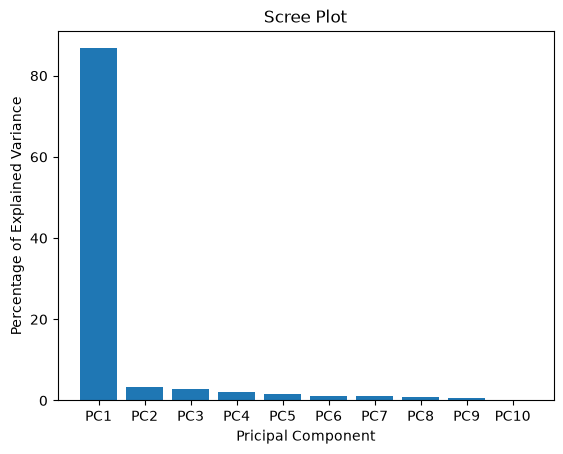

In [14]:
# Now we use matplotlib to create a bat plot
plt.bar(x = range(1,len(per_var)+1),height = per_var,tick_label = labels)
plt.ylabel("Percentage of Explained Variance")
plt.xlabel("Pricipal Component")
plt.title("Scree Plot")
plt.show()

In [25]:
# To draw a PCA plot, we'll first put the new coordinates, created by pca.transform(scaled.data),
#into a nice matrix where the rows have sample labels and columns have PC labels
pca_df = pd.DataFrame(pca_data,index=[*wt, *ko], columns=labels)
pca_df

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
wt1,-9.614882,2.073127,-1.803982,-0.188592,-1.032445,-1.000799,1.041883,0.514755,1.149992,-1.239612e-15
wt2,-9.168821,0.676475,0.219255,1.396481,-0.643604,2.700772,-0.362020,0.534923,-0.118944,-2.738413e-15
wt3,-9.228688,-2.254601,1.981140,-0.479483,-1.433989,-0.319980,0.871967,-1.484288,-0.292743,-3.293524e-15
wt4,-9.230147,3.040686,0.537374,-1.294292,1.601868,-0.522398,-0.910881,-0.611436,-0.775990,1.258390e-15
wt5,-9.311485,-3.556668,-0.835530,0.571782,1.604918,-0.795524,-0.605461,1.022483,0.042023,-2.959222e-16
ko1,8.979615,-0.462597,-2.408906,0.437666,-1.053740,-0.143225,-1.769549,-1.215082,0.271080,2.701680e-15
ko2,9.756447,0.460954,2.130500,1.387203,1.762443,0.159555,0.409396,-0.636753,1.164793,4.812339e-16
ko3,9.285779,0.493837,-1.520000,1.704256,0.236668,-0.391177,1.470564,0.075880,-1.311217,2.257591e-15
ko4,9.071143,0.498507,2.557807,-0.253474,-1.530569,-0.924880,-0.822654,1.470689,-0.234098,1.258390e-15
ko5,9.461040,-0.969720,-0.857658,-3.281547,0.488449,1.237657,0.676754,0.328829,0.105104,1.036345e-15


In [16]:
# Draw scatter plot with title and nice axis labels
#plt.scatter(pca_df.PC1,pca_df.PC2)
#plt.title('My PCA Graph')
#plt.xlabel('PC1 - {0}%'.format(per_var[0]))
#plt.ylabel('PC2 - {0}%'.format(per_var[0])) 

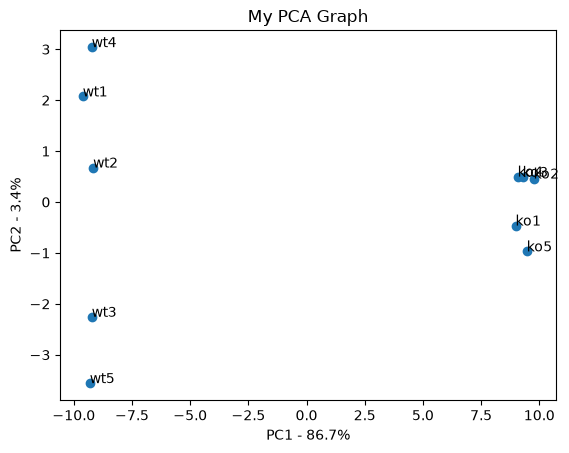

In [17]:
plt.scatter(pca_df.PC1,pca_df.PC2)
plt.title('My PCA Graph')
plt.xlabel('PC1 - {0}%'.format(per_var[0]))
plt.ylabel('PC2 - {0}%'.format(per_var[1])) 

# This loop adds sample names to the graph
for sample in pca_df.index:
    plt.annotate(sample, (pca_df.PC1.loc[sample], pca_df.PC2.loc[sample]))
plt.show() # we dispaly the graph

In [26]:
# We'll start by craeting a pandas "Series" object with the loading scores in PC1.
loading_scores = pd.Series(pca.components_[0], index = genes) # NOTE : the PCs are zero-indexed, so PC1 = 0.
loading_scores

gene1     -0.107307
gene2      0.107114
gene3      0.106419
gene4     -0.107196
gene5      0.086867
             ...   
gene96    -0.105746
gene97    -0.093969
gene98     0.105898
gene99    -0.088417
gene100    0.107208
Length: 100, dtype: float64

In [27]:
sorted_loading_scores = loading_scores.abs().sort_values(ascending=False) # now we sort the loading scores based on their magnitude (absolute value)
sorted_loading_scores

gene41    0.107312
gene16    0.107307
gene1     0.107307
gene91    0.107305
gene92    0.107288
            ...   
gene35    0.022753
gene62    0.021858
gene7     0.018942
gene65    0.018504
gene68    0.005330
Length: 100, dtype: float64

In [28]:
# Here we are just getting the names of the top 10 indexes (which are the gene names)
top_10_genes = sorted_loading_scores[0:10].index.values
top_10_genes

<ArrowStringArray>
['gene41', 'gene16',  'gene1', 'gene91', 'gene92', 'gene70', 'gene37',
 'gene93',  'gene8', 'gene60']
Length: 10, dtype: str

In [21]:
# Lastly print out the top 10 gene names and their corresponding loading scores
print(loading_scores[top_10_genes])

gene41    0.107312
gene16   -0.107307
gene1    -0.107307
gene91   -0.107305
gene92   -0.107288
gene70   -0.107276
gene37   -0.107275
gene93   -0.107265
gene8     0.107265
gene60   -0.107243
dtype: float64


In [22]:
pwd

'C:\\Users\\JAFFAR\\Home\\Machine Learning\\PCA'